# Parameter sensitivity: evaluate the released checkpoints

Each point is one trained model of the proposed method with one hyper-parameter changed (all others at their defaults).
This notebook only loads the released checkpoints in `checkpoints/` and evaluates them on the test set; it does not train.
`points.csv` lists, for every point, the parameter value, the checkpoint and the test accuracy recorded during GPU training.

Notes (also in the README):
- each point is evaluated on the 62,002-window test set using its released checkpoint in `checkpoints/`;
- the four default points (ρ = 0.9, τ₁ = 0.07, β = 0.25, α = 0.9) are the same model.

In [1]:
import os, sys, json
from pathlib import Path
sys.path.insert(0, str(Path("..").resolve() / "common"))
import core as C
import numpy as np, pandas as pd, torch
print("torch", torch.__version__, "| device", C.DEVICE)

torch 2.8.0+cu129 | device cuda


In [2]:
@torch.no_grad()
def predict(net, X, bs=2048):
    net.eval()
    X = torch.from_numpy(X)
    return torch.cat([net(X[i:i + bs].to(C.DEVICE)).argmax(1).cpu() for i in range(0, len(X), bs)]).numpy()


def build(mode, S, S11):
    spec = C.ABL[mode]
    Sx = S if spec["data"] == "full" else S11
    nf = len(Sx["feats"])
    if spec["p1"] is None:
        net = C.PureBaselineMLP(nf, 4, spec["hidden"])
    else:
        net = C.DownstreamClassifier(C.make_encoder(spec["enc"], nf), 4, freeze_encoder=True)
    return net.to(C.DEVICE), Sx

In [3]:
pts = pd.read_csv("points.csv", dtype={"value": str})
S, _ = C.prepare("../data/features_21d", verbose=False)
cache = {}
for ck in pts["checkpoint"].unique():
    net, _ = build("M5", S, None)
    net.load_state_dict(torch.load("checkpoints/" + ck, map_location="cpu"))
    cache[ck] = int((predict(net, S["X_test"]) == S["y_test"]).sum())
pts["test_correct_here"] = pts["checkpoint"].map(cache)
pts["test_acc_here_%"] = (100 * pts["test_correct_here"] / len(S["y_test"])).round(4)
pts[["parameter", "value", "test_acc_recorded_%", "test_acc_here_%"]]

[OK]   self-test: one value changed by 1e-9 -> rejected (test: feature digest mismatch)
[OK]   self-test: columns reordered -> rejected (test: column names/order mismatch.)


,parameter,value,test_acc_recorded_%,test_acc_here_%
0,rho,0.4,98.408116,98.4097
1,rho,0.6,98.825844,98.8291
2,rho,0.8,98.983904,98.9823
3,rho,0.9,99.445179,99.4452
4,rho,1.0,98.567788,98.5678
5,tau_1,0.06,98.383923,98.3839
6,tau_1,0.07,99.445179,99.4452
7,tau_1,0.085,99.161317,99.1597
8,tau_1,0.1,99.032289,99.0307
9,tau_1,0.2,99.030676,99.0307


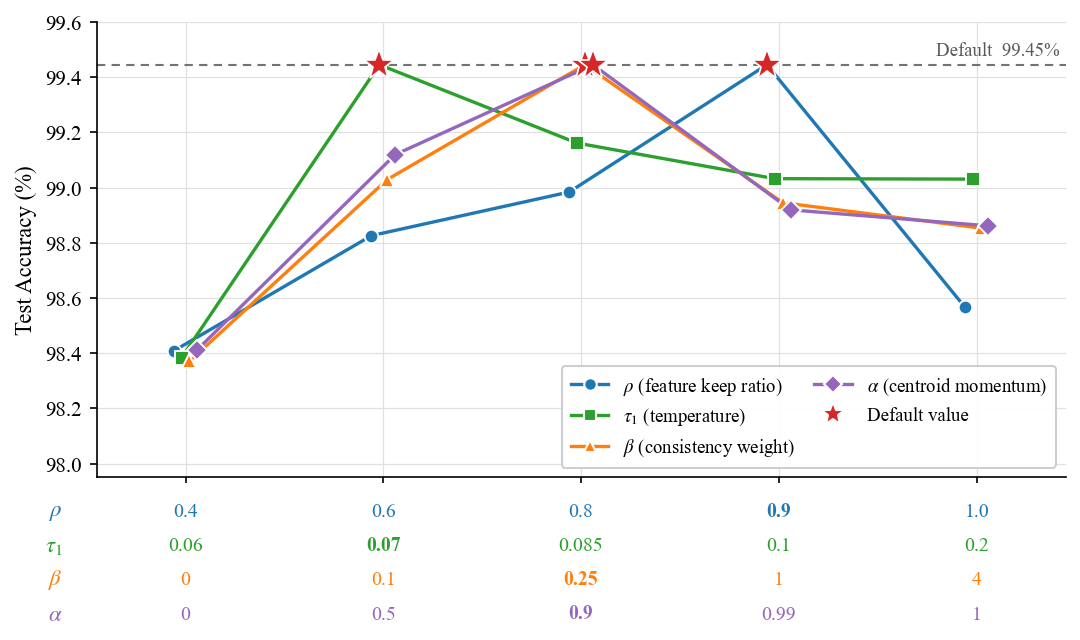

In [4]:
# figure: the recorded (GPU) accuracies, same values as reported in the paper
import logging
logging.getLogger("fontTools").setLevel(logging.ERROR)
import matplotlib.pyplot as plt
from matplotlib import font_manager as fm
from matplotlib.transforms import blended_transform_factory
from matplotlib.lines import Line2D
%matplotlib inline

if "times" in fm.findfont(fm.FontProperties(family="Times New Roman")).lower():
    plt.rcParams["font.family"] = "Times New Roman"
plt.rcParams.update({"mathtext.fontset": "stix", "font.size": 10, "pdf.fonttype": 42})

STYLE = {"rho":   (r"$\rho$",   "feature keep ratio", "#1f77b4", "o"),
         "tau_1": (r"$\tau_1$", "temperature",        "#2ca02c", "s"),
         "beta":  (r"$\beta$",  "consistency weight", "#ff7f0e", "^"),
         "alpha": (r"$\alpha$", "centroid momentum",  "#9467bd", "D")}
OFF = {"rho": -0.06, "tau_1": -0.02, "beta": 0.02, "alpha": 0.06}
X = np.arange(5)
BASE = float(pts.loc[pts.is_default, "test_acc_recorded_%"].iloc[0])

fig, ax = plt.subplots(figsize=(7.6, 4.6))
fig.subplots_adjust(left=0.13, right=0.98, top=0.97, bottom=0.31)
ax.axhline(BASE, color="0.45", ls=(0, (4, 3)), lw=1.0, zorder=1)
ax.text(4.42, BASE + 0.018, "Default  %.2f%%" % BASE, ha="right", va="bottom", fontsize=9, color="0.35")
for p, (sym, name, col, mk) in STYLE.items():
    g = pts[pts.parameter == p].sort_values("position")
    xo = X + OFF[p]
    ys = g["test_acc_recorded_%"].values
    ax.plot(xo, ys, color=col, lw=1.6, zorder=2)
    ax.plot(xo, ys, ls="", marker=mk, ms=6.5, mfc=col, mec="white", mew=0.9, zorder=3)
    d = int(np.flatnonzero(g.is_default.values)[0])
    ax.plot(xo[d], ys[d], ls="", marker="*", ms=15, mfc="#d62728", mec="white", mew=0.8, zorder=4)
ax.set_xlim(-0.45, 4.45); ax.set_ylim(97.95, 99.6)
ax.set_xticks(X); ax.set_xticklabels([]); ax.tick_params(axis="x", length=3)
ax.set_ylabel("Test Accuracy (%)", fontsize=11)
ax.grid(axis="both", color="0.88", lw=0.6); ax.set_axisbelow(True)
for s in ("top", "right"):
    ax.spines[s].set_visible(False)
tr = blended_transform_factory(ax.transData, ax.transAxes)
for r, (p, (sym, name, col, mk)) in enumerate(STYLE.items()):
    g = pts[pts.parameter == p].sort_values("position")
    yy = -0.075 - 0.075 * r
    ax.text(-0.62, yy, sym, transform=tr, ha="right", va="center", fontsize=11, color=col)
    for x, v, dflt in zip(X, g["value"], g["is_default"]):
        ax.text(x, yy, v, transform=tr, ha="center", va="center", fontsize=9.5, color=col,
                fontweight="bold" if dflt else "normal")
hs = [Line2D([], [], color=c, lw=1.6, marker=m, ms=6, mfc=c, mec="white", label=s + " (" + n + ")")
      for s, n, c, m in STYLE.values()]
hs.append(Line2D([], [], ls="", marker="*", ms=12, mfc="#d62728", mec="white", label="Default value"))
ax.legend(handles=hs, loc="lower right", ncol=2, frameon=True, framealpha=0.95, edgecolor="0.8",
          fontsize=9, handlelength=2.0, columnspacing=1.0, borderpad=0.5)
fig.savefig("fig_sensitivity.png", dpi=300, bbox_inches="tight")
fig.savefig("fig_sensitivity.pdf", bbox_inches="tight")
plt.show()